In [37]:
from __future__ import annotations
import numpy as np
import torch
from torch import nn

PATH = "../.."
# PATH = "storage"

In [38]:
import os
import sys
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import train_test_split

github_path = r"C:\Users\Dhyey\Documents\University\MSc\CS907 Dissertation Project\Tutorials\third_party\EXAONEPath"
sys.path.append(github_path)
from vision_transformer import VisionTransformer
from huggingface_hub import login, hf_hub_download
from reetoolbox.loadmodels import *
# — login once per session —
hf_token = os.environ.get("HF_TOKEN")
if not hf_token:
    raise RuntimeError("Please set HF_TOKEN in your environment")
login(token=hf_token, add_to_git_credential=True)


from reetoolbox.dataloaders import *
from reetoolbox.loadmodels import *
from reetoolbox.eval_funcs import *

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [39]:
DATASET_CLASSES = {
    "NCT": NCTDataSet,
    "PanNuke": PanNukeDataset,
    "PANDA": PandaDataset,
}

DATASET_PARAMS = {
    "NCT": {
        "root_dir": os.path.join(PATH, 'data', 'NCT', 'NCT-CRC-HE-100K'),
        "batch_size": 16,
        "trainval_multiplier": 0.05,
        "trainval_size": 0.3,
        "extra_kwargs": dict(classification_mode='tum_vs_all'),
    },
    "PanNuke": {
        "root_dir": os.path.join(PATH, 'data', 'PanNuke'),
        "batch_size": 16,
        "trainval_multiplier": 0.999,
        "trainval_size": 0.3,
        "extra_kwargs": dict(folds=(1, 2), min_positive=5),
    },
    "MIDOGpp": {
        "root_dir": os.path.join(PATH, 'data', "MIDOGpp"),
        "batch_size": 16,
        "trainval_multiplier": 0.11,
        "trainval_size": 0.3,
        "extra_kwargs": dict(split='train'),
    },
}

In [40]:
dataset_name = "NCT"
# dataset_name = "PanNuke"
# dataset_name = "MIDOGpp"

params = DATASET_PARAMS[dataset_name]
dataset_class = DATASET_CLASSES[dataset_name]

In [41]:
resnet_datadict = create_trainval_dict(
    dataset_class=dataset_class,
    root_dir=params["root_dir"],
    batch_size=params["batch_size"],
    # transform=model_transforms["ResNet18"],
    transform=transforms.ToTensor(),
    trainval_multiplier=params["trainval_multiplier"],
    trainval_size=params["trainval_size"],
    **params["extra_kwargs"]
)

train_loader = resnet_datadict["train"]

Train batches: 219
 Val batches: 94


In [42]:
dataset_name = "NCT"
batch_size           = 8
mode                 = 'tum_vs_all'
test_multiplier      = 0.05
test_root            = os.path.join(PATH, 'data', 'NCT', 'CRC-VAL-HE-7K')
mode                 = 'tum_vs_all'

test_data, test_loader = build_dataset(
    NCTDataSet,
    root_dir=test_root,
    batch_size=batch_size,
    test_multiplier=test_multiplier,
    # transform=model_transforms["ResNet18"],
    transform=transforms.ToTensor(),
    classification_mode=mode,
    shuffle=False
)

print(f"Test batches: {len(test_loader)}")

Test batches: 45


In [43]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics.pairwise import cosine_similarity
from torchvision import transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

from transformers import AutoImageProcessor, AutoModelForImageClassification

image_processor = AutoImageProcessor.from_pretrained("microsoft/resnet-18")
model = AutoModelForImageClassification.from_pretrained("microsoft/resnet-18").to(device).eval()

def get_embeddings(model, processor, dataloader, device, img_transform=None):
    all_embeddings = []
    all_labels = []
    all_names = []
    with torch.no_grad():
        for batch in tqdm(dataloader, leave=False):
            imgs, labels, names = batch
            # Convert each tensor to PIL, apply blur if provided, then process
            img_pil = []
            for img in imgs:
                img_pil_single = transforms.ToPILImage()(img)
                if img_transform is not None:
                    img_pil_single = img_transform(img_pil_single)
                img_pil.append(img_pil_single)
            inputs = processor(img_pil, return_tensors="pt").to(device)
            outputs = model(**inputs, output_hidden_states=True)
            emb = outputs.hidden_states[-1]
            if emb.ndim > 2:
                emb = emb.view(emb.shape[0], -1)
            all_embeddings.append(emb.cpu())
            all_labels.append(labels.cpu())
            all_names.extend(names)
    embeddings = torch.cat(all_embeddings, dim=0).numpy()
    labels = torch.cat(all_labels, dim=0).numpy()
    return embeddings, labels, all_names

# --- PIL-based blur ---
def blur_pil_image(img_pil, sigma=2, ksize=11):
    blur = transforms.GaussianBlur(kernel_size=(ksize, ksize), sigma=sigma)
    img_tensor = transforms.ToTensor()(img_pil)
    img_blur = blur(img_tensor)
    img_blur = img_blur.clamp(0, 1)  # Ensure valid range
    img_blur_pil = transforms.ToPILImage()(img_blur)
    return img_blur_pil

# --- Get train embeddings (once, no blur) ---
train_embeddings, train_labels, train_names = get_embeddings(model, image_processor, train_loader, device)
train_embeddings = train_embeddings.reshape(train_embeddings.shape[0], -1)

# --- Loop over sigma values ---
import math

sigma_values = np.linspace(0, 14, 20)
mean_similarities = []
all_test_embeddings = []
embeddings_for_tsne = []

N_TSNE_SIGMA = 5

for idx, sigma in enumerate(tqdm(sigma_values, desc="Blur sigma sweep")):
    k_size = max(3, math.ceil(6 * sigma + 1))
    if k_size % 2 == 0: k_size += 1  # ensure odd

    if sigma == 0:
        blur_transform = None
    else:
        blur_transform = lambda img: blur_pil_image(img, sigma=sigma, ksize=k_size)
    
    test_embeddings, _, _ = get_embeddings(model, image_processor, test_loader, device, img_transform=blur_transform)
    test_embeddings = test_embeddings.reshape(test_embeddings.shape[0], -1)
    all_test_embeddings.append(test_embeddings)

    sim_matrix = cosine_similarity(test_embeddings, train_embeddings)
    mean_test_sim = sim_matrix.mean(axis=1)
    mean_similarities.append(mean_test_sim.mean())

    if idx % N_TSNE_SIGMA == 0 or idx == len(sigma_values)-1:
        embeddings_for_tsne.append((sigma, test_embeddings))


Blur sigma sweep: 100%|██████████| 20/20 [05:49<00:00, 17.48s/it]


In [44]:
import matplotlib.patches as mpatches

def plot_cov_ellipse(mean, cov, ax, n_std=2.0, edgecolor='k', **kwargs):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:,0][::-1]))
    width, height = 2 * n_std * np.sqrt(vals)
    ellipse = mpatches.Ellipse(xy=mean, width=width, height=height, angle=theta, 
                               edgecolor=edgecolor, facecolor='none', lw=2, **kwargs)
    ax.add_patch(ellipse)


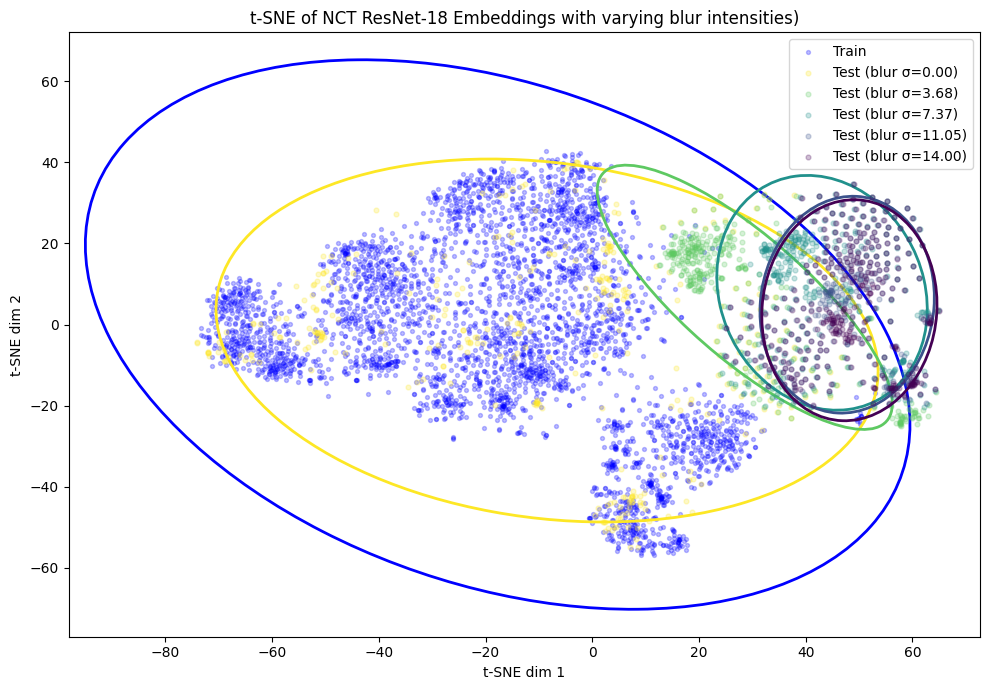

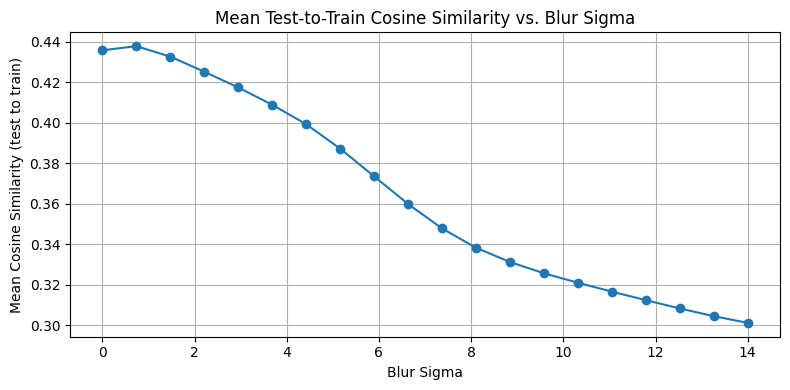

In [45]:
from sklearn.manifold import TSNE
import matplotlib.patches as mpatches

# --- t-SNE plot with ellipses ---

tsne_input = [train_embeddings] + [emb for (sigma, emb) in embeddings_for_tsne]
tsne_input_stacked = np.concatenate(tsne_input, axis=0)
n_train = len(train_embeddings)
offset = n_train
color_map = plt.cm.viridis(np.linspace(0, 1, len(embeddings_for_tsne)))
color_map = color_map[::-1]

# t-SNE directly on full embeddings
tsne_emb_all = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(tsne_input_stacked)

plt.figure(figsize=(10,7))
ax = plt.gca()
sc1 = plt.scatter(tsne_emb_all[:n_train,0], tsne_emb_all[:n_train,1], c='blue', alpha=0.25, label="Train", s=8)

# Ellipse for train cluster
train_data = tsne_emb_all[:n_train]
if n_train > 2:
    mean_train = train_data.mean(axis=0)
    cov_train = np.cov(train_data, rowvar=False)
    plot_cov_ellipse(mean_train, cov_train, ax, n_std=3, edgecolor='blue')

offset = n_train
scatter_handles = [sc1]
labels = ["Train"]

for i, (sigma, emb) in enumerate(embeddings_for_tsne):
    n_test = len(emb)
    data = tsne_emb_all[offset:offset+n_test]
    sc = plt.scatter(data[:,0], data[:,1], color=color_map[i], label=f"Test (blur σ={sigma:.2f})", s=12, alpha=0.25)
    scatter_handles.append(sc)
    labels.append(f"Test (blur σ={sigma:.2f})")
    # Ellipse for test group
    if n_test > 2:
        mean = data.mean(axis=0)
        cov = np.cov(data, rowvar=False)
        plot_cov_ellipse(mean, cov, ax, n_std=2, edgecolor=color_map[i])
    offset += n_test

plt.legend(handles=scatter_handles, labels=labels)
plt.title("t-SNE of NCT ResNet-18 Embeddings with varying blur intensities)")
plt.xlabel("t-SNE dim 1")
plt.ylabel("t-SNE dim 2")
plt.tight_layout()
plt.show()

# --- Similarity vs. sigma line plot ---
plt.figure(figsize=(8,4))
plt.plot(sigma_values, mean_similarities, marker='o')
plt.title("Mean Test-to-Train Cosine Similarity vs. Blur Sigma")
plt.xlabel("Blur Sigma")
plt.ylabel("Mean Cosine Similarity (test to train)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [46]:
# import torch
# import numpy as np
# import matplotlib.pyplot as plt
# from tqdm import tqdm
# from sklearn.metrics.pairwise import cosine_similarity
# from sklearn.decomposition import PCA
# from torchvision import transforms

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# from transformers import AutoImageProcessor, AutoModelForImageClassification

# image_processor = AutoImageProcessor.from_pretrained("microsoft/resnet-18")
# model = AutoModelForImageClassification.from_pretrained("microsoft/resnet-18").to(device).eval()

# def blur_tensor_image(img, sigma=2, ksize=11):
#     blur = transforms.GaussianBlur(kernel_size=(ksize, ksize), sigma=sigma)
#     img = img.clone()
#     if img.max() > 1:
#         img = img / 255.
#     img_blur = blur(img)
#     return img_blur

# def get_embeddings(model, processor, dataloader, device, img_transform=None):
#     all_embeddings = []
#     all_labels = []
#     all_names = []
#     with torch.no_grad():
#         for batch in tqdm(dataloader, leave=False):
#             imgs, labels, names = batch
#             # Apply blur or any transform if provided
#             if img_transform is not None:
#                 imgs = torch.stack([img_transform(img) for img in imgs])
#             img_pil = [transforms.ToPILImage()(img) for img in imgs]
#             inputs = processor(img_pil, return_tensors="pt").to(device)
#             outputs = model(**inputs, output_hidden_states=True)
#             emb = outputs.hidden_states[-1]
#             if emb.ndim > 2:
#                 emb = emb.view(emb.shape[0], -1)
#             all_embeddings.append(emb.cpu())
#             all_labels.append(labels.cpu())
#             all_names.extend(names)
#     embeddings = torch.cat(all_embeddings, dim=0).numpy()
#     labels = torch.cat(all_labels, dim=0).numpy()
#     return embeddings, labels, all_names

# # --- Get train embeddings (once, no blur) ---
# train_embeddings, train_labels, train_names = get_embeddings(model, image_processor, train_loader, device)
# train_embeddings = train_embeddings.reshape(train_embeddings.shape[0], -1)

# # --- Loop over sigma values ---
# import math

# sigma_values = np.linspace(0, 7, 20)
# mean_similarities = []
# all_test_embeddings = []
# embeddings_for_pca = []

# N_PCA_SIGMA = 5  # Show every Nth blur for test in PCA

# for idx, sigma in enumerate(tqdm(sigma_values, desc="Blur sigma sweep")):
#     k_size = math.ceil(6 * sigma + 1)
#     if k_size % 2 == 0: k_size += 1  # ensure odd

#     # Skip blur if sigma == 0 (identity)
#     if sigma == 0:
#         blur_transform = lambda x: x
#     else:
#         blur_transform = lambda img: blur_tensor_image(img, sigma=sigma, ksize=k_size)
    
#     test_embeddings, _, _ = get_embeddings(model, image_processor, test_loader, device, img_transform=blur_transform)
#     test_embeddings = test_embeddings.reshape(test_embeddings.shape[0], -1)
#     all_test_embeddings.append(test_embeddings)

#     # Cosine similarity (test to train)
#     sim_matrix = cosine_similarity(test_embeddings, train_embeddings)
#     mean_test_sim = sim_matrix.mean(axis=1)
#     mean_similarities.append(mean_test_sim.mean())

#     # For PCA plot, store some test embeddings
#     if idx % N_PCA_SIGMA == 0 or idx == len(sigma_values)-1:
#         embeddings_for_pca.append((sigma, test_embeddings))

In [47]:
# import matplotlib.patches as mpatches

# def plot_cov_ellipse(mean, cov, ax, n_std=2.0, edgecolor='k', **kwargs):
#     """
#     Plots an ellipse representing the covariance matrix centered at mean.
#     n_std: Number of standard deviations for the ellipse radius (e.g., 2 for ~95%).
#     """
#     vals, vecs = np.linalg.eigh(cov)
#     order = vals.argsort()[::-1]
#     vals, vecs = vals[order], vecs[:, order]
#     theta = np.degrees(np.arctan2(*vecs[:,0][::-1]))
#     width, height = 2 * n_std * np.sqrt(vals)
#     ellipse = mpatches.Ellipse(xy=mean, width=width, height=height, angle=theta, 
#                                edgecolor=edgecolor, facecolor='none', lw=2, **kwargs)
#     ax.add_patch(ellipse)

In [48]:
# from sklearn.manifold import TSNE
# import matplotlib.patches as mpatches

# pca_input = [train_embeddings] + [emb for (sigma, emb) in embeddings_for_pca]
# pca_input_stacked = np.concatenate(pca_input, axis=0)
# n_train = len(train_embeddings)
# offset = n_train
# color_map = plt.cm.viridis(np.linspace(0, 1, len(embeddings_for_pca)))
# color_map = color_map[::-1]

# # --- t-SNE plot with ellipses and PCA variance explained annotation ---

# pca = PCA(n_components=65)
# tsne_input = pca.fit_transform(pca_input_stacked)
# pca_var = np.sum(pca.explained_variance_ratio_)
# pca_var_str = f"PCA({pca.n_components_}) variance explained: {pca_var*100:.1f}%"

# tsne_emb_all = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(tsne_input)

# plt.figure(figsize=(10,7))
# ax = plt.gca()
# sc1 = plt.scatter(tsne_emb_all[:n_train,0], tsne_emb_all[:n_train,1], c='blue', alpha=0.25, label="Train", s=8)

# # --- Add ellipse for train cluster ---
# train_data = tsne_emb_all[:n_train]
# if n_train > 2:
#     mean_train = train_data.mean(axis=0)
#     cov_train = np.cov(train_data, rowvar=False)
#     plot_cov_ellipse(mean_train, cov_train, ax, n_std=2, edgecolor='blue')

# offset = n_train
# scatter_handles = [sc1]
# labels = ["Train"]

# for i, (sigma, emb) in enumerate(embeddings_for_pca):
#     n_test = len(emb)
#     data = tsne_emb_all[offset:offset+n_test]
#     sc = plt.scatter(data[:,0], data[:,1], color=color_map[i], label=f"Test (blur σ={sigma:.2f})", s=8, alpha=0.25)
#     scatter_handles.append(sc)
#     labels.append(f"Test (blur σ={sigma:.2f})")
#     # Add ellipse for each test group
#     if n_test > 2:
#         mean = data.mean(axis=0)
#         cov = np.cov(data, rowvar=False)
#         plot_cov_ellipse(mean, cov, ax, n_std=2, edgecolor=color_map[i])
#     offset += n_test

# # Add PCA variance explained as a legend entry
# handles = scatter_handles + [mpatches.Patch(facecolor='none', edgecolor='none', label=pca_var_str)]
# plt.legend(handles=handles, labels=labels+[pca_var_str])

# plt.title("t-SNE of ResNet-18 Embeddings (varying blur σ)")
# plt.xlabel("t-SNE dim 1")
# plt.ylabel("t-SNE dim 2")
# plt.tight_layout()
# plt.show()
